# 01-RTOS基础与FreeRTOS课程概览


## 1. 课程定位与学习目标

《FreeRTOS 从入门到实战》以平衡球项目为实战对象，先学习实时操作系统内核的基本原理，再把 FreeRTOS 移植到已有嵌入式项目中。课程关注任务怎样运行、怎样协作，以及工程移植中怎样处理配置、时钟和共享资源问题。

本篇对应 `01课程介绍.pptx` 和 `02freeRTOS介绍.pptx`，是十七篇笔记中的第 **01** 篇。先建立课程全貌，再按课件顺序理解裸机开发的局限、RTOS 的实时性、FreeRTOS 的定位及核心模块。

课件提出的学习目标可以归纳为以下几项。

| 学习目标 | 需要建立的认识或完成的工作 |
|---|---|
| 掌握内核概念 | 理解任务、调度、通信和同步之间的关系 |
| 使用核心功能 | 学会创建任务，使用信号量、消息队列等机制组织任务协作 |
| 解决移植问题 | 排查开发环境配置和 `SysTick` 适配等常见问题 |
| 完成项目移植 | 将 FreeRTOS 引入平衡球项目，形成可以运行的 RTOS 工程 |
| 建立系统框架 | 了解任务管理、通信、内存、中断和软件定时器五大模块 |
| 获取学习资料 | 能从官网查找源码、文档和相关学习资源 |

课程强调通过小案例理解功能，再用于完整项目。创建几个任务只是起点，还需要处理任务之间的同步、共享资源竞争，以及课件后续讨论的优先级反转问题。


## 2. 课程路线与工具准备

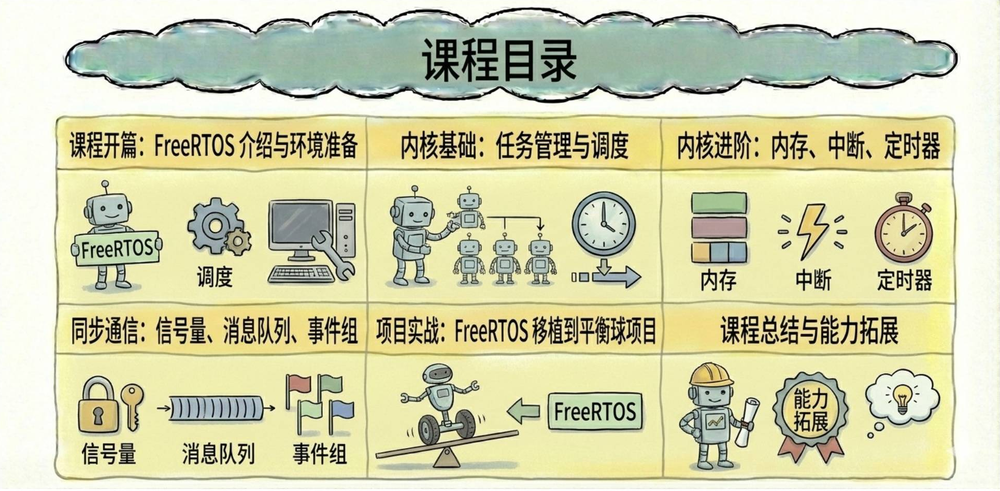

*来源：`01课程介绍.pptx` 第4页，保留课程目录，裁去页眉页脚。*

原课程按“环境与移植 → 任务与调度 → 内核进阶 → 同步通信 → 项目实战”展开。十七篇笔记沿用这个学习顺序。

| 原课程阶段 | 要解决的问题 | 对应笔记 |
|---|---|---|
| 课程开篇与环境准备 | 为什么需要 FreeRTOS？源码怎样引入工程并完成移植？ | 01—03 |
| 内核基础：任务管理与调度 | 怎样创建任务、管理状态、安排优先级？任务栈和调度器怎样工作？ | 04—06 |
| 内核进阶 | 怎样处理资源竞争、内存分配、中断和软件定时器？ | 07—10 |
| 同步通信 | 怎样在任务之间传递通知、数据并协调共享资源？ | 11—16 |
| 项目实战 | 怎样把已经学会的机制应用到平衡球项目？ | 17 |

课件给出的学习路径是：先搭好开发环境并排除移植障碍，再学习内核功能、完成小案例，最后结合视频改造平衡球项目。

课程介绍列出的工具准备如下。

| 工具或资料 | 用途 |
|---|---|
| GD32 开发板 | 运行课程中的嵌入式程序和验证案例 |
| Keil/MDK 开发环境 | 配置、编译和调试工程 |
| 平衡球项目源码 | 作为后续引入 FreeRTOS 的项目基础 |

这一页只列出工具类别。具体芯片、源码版本、目录结构和工程配置在环境准备与移植课件中展开，按第02、03篇记录的实际步骤操作。


## 3. 最终实战对象：平衡球项目

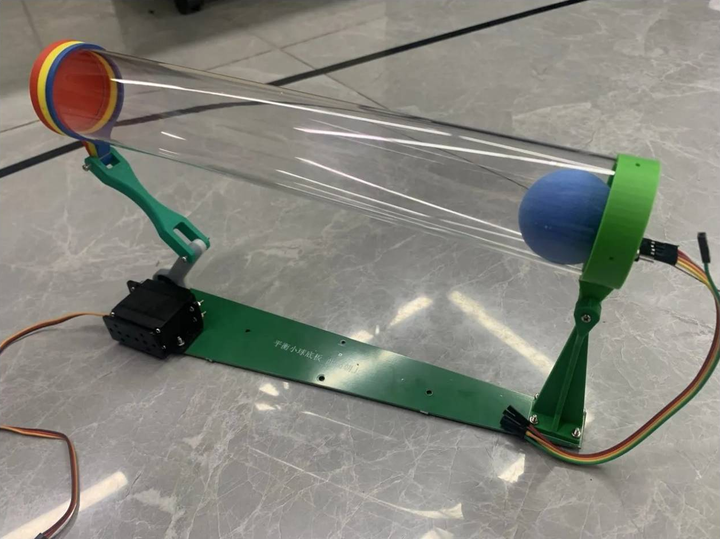

*来源：`01课程介绍.pptx` 第6页的项目实物照片。*

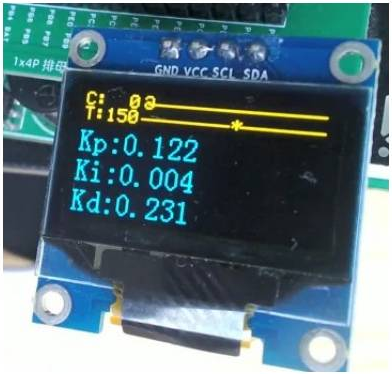

*来源：`01课程介绍.pptx` 第7页的显示界面。*

课件展示了平衡球装置及带有 `Kp`、`Ki`、`Kd` 字段的显示界面，用来说明课程最终改造的项目对象。本节只建立项目背景；图中参数不作为后续工程的通用配置值。

课程希望通过这个项目完成三件事：理解 FreeRTOS 内核怎样组织任务，解决移植、同步和资源竞争中的实际问题，最终得到一个可以运行的项目。

第17篇单独整理平衡球项目实战。资料目录中没有与这一节对应的独立 PPT，具体改造过程需要结合最后一节视频及项目代码。


## 4. 为什么需要FreeRTOS：多任务与并发

裸机程序是没有引入操作系统内核、由应用代码直接组织运行流程的程序。课件从裸机局限出发：当设备同时需要处理多项工作时，仅靠一条顺序执行流程，很容易出现某项工作等待过久、响应时间不稳定的问题。

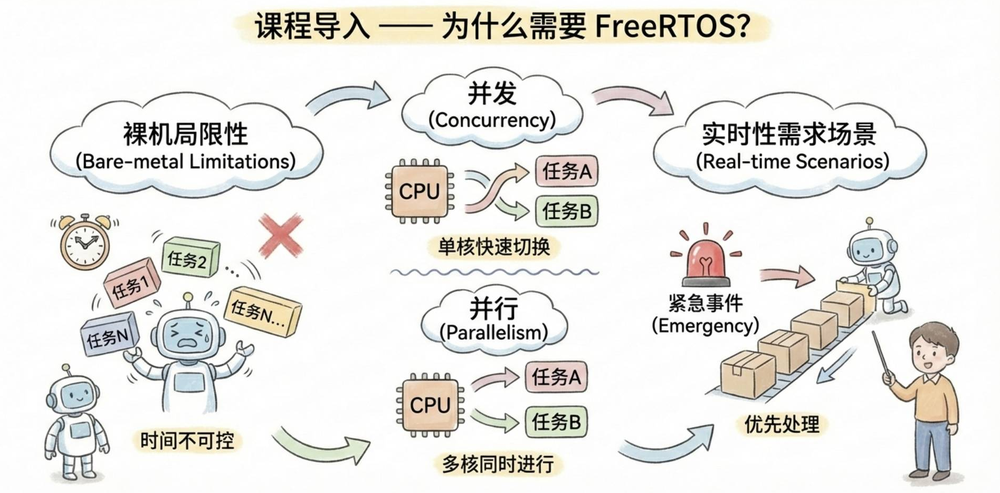

*来源：`02freeRTOS介绍.pptx` 第4页，裁去页眉页脚。*

图中区分了两个容易混淆的概念。

| 概念 | 含义 | 课件中的示意 |
|---|---|---|
| 并发（Concurrency） | 多项工作在同一段时间内交替推进 | 单核处理器在任务A、任务B之间快速切换 |
| 并行（Parallelism） | 多项工作在同一时刻实际执行 | 多核处理器同时运行不同任务 |

在课程使用的单核 MCU 上，多任务通常依靠处理器在任务之间切换。同一时刻只有一个任务占用处理器执行，不能把“创建了多个任务”理解成多个任务同时执行。

引入 RTOS 后，调度器负责决定哪个任务获得处理器。应用可以按各项工作的职责组织任务，再根据紧急程度、运行状态和调度规则安排它们执行。

课件把这一需求与实时场景联系起来：出现紧急事件时，希望更紧急的工作及时得到处理，而不是一直等待普通工作执行完毕。


## 5. 裸机多任务调度的典型痛点

课件以按键扫描、协议解析和 `balance` 任务为例，比较裸机轮询与 RTOS 调度。

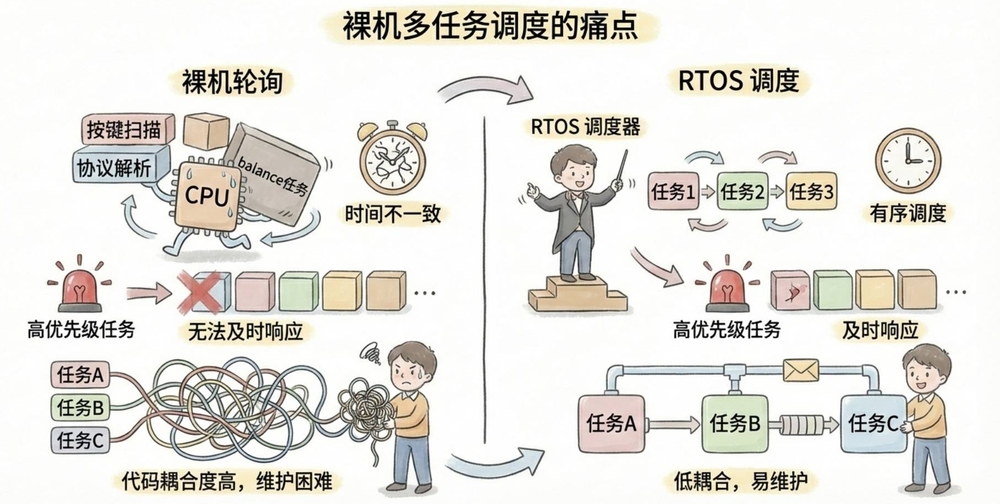

*来源：`02freeRTOS介绍.pptx` 第5页，裁去页眉页脚。*

### 5.1 各项工作的执行时间相互影响

在轮询结构中，一项工作通常要等待前面的代码运行到相应位置才能执行。如果协议解析耗时发生变化，后面的按键扫描或平衡控制就可能推迟。

随着功能增加，每轮执行时间不再固定，任务之间的时间关系也更难维护。课件用“时间不一致”概括这一问题。

### 5.2 紧急工作不能及时获得执行机会

仅按固定顺序轮询时，某项工作即使更紧急，也不一定能够及时执行。程序还没有运行到对应检查位置，事件就只能继续等待。

在启用抢占式调度的 RTOS 中，已经就绪的高优先级任务可以抢占低优先级任务，从而优先处理更紧急的工作。这里的**就绪**表示任务已经具备运行条件，正在等待处理器。

### 5.3 代码耦合增加，维护变困难

当多项工作的时序、状态和数据交互都集中在同一个流程中，修改一个功能往往会影响其他功能的执行时机。课件将其概括为“代码耦合度高，维护困难”。

| 裸机轮询中的问题 | RTOS 提供的组织方式 |
|---|---|
| 每轮耗时受各段代码影响 | 由调度器统一管理任务执行机会 |
| 紧急工作受轮询顺序限制 | 通过优先级和抢占式调度组织响应 |
| 多个功能的流程交织在一起 | 按职责拆成任务，通过通信与同步机制协作 |

这些是课件强调的结构改进。任务的划分、优先级和共享资源保护仍需要应用正确设计。


## 6. RTOS与FreeRTOS的基本定位

### 6.1 RTOS是什么

**RTOS（Real-Time Operating System，实时操作系统）**用于组织任务运行，并支持应用在规定的时间要求内响应事件。课件突出任务调度、时间片和优先级抢占这些机制。

调度器可以根据任务的运行条件选择下一项工作；任务优先级表达执行的先后关系；时间片调度则让符合条件的同优先级任务交替获得执行机会。后续任务管理课件会进一步说明这些机制。

### 6.2 FreeRTOS是什么

**FreeRTOS** 是面向嵌入式设备的开源、轻量、可移植的实时操作系统内核。课件强调它适合资源受限的 MCU，并以 ARM、RISC-V 说明跨处理器架构移植的能力。

| 课件强调的特点 | 在学习和开发中的意义 |
|---|---|
| 开源 | 可以获取源码，阅读内核实现并结合工程学习 |
| 轻量、资源占用低 | 适合内存和处理器资源有限的设备 |
| 可移植 | 通过适配处理器及工具链相关部分，支持不同平台 |
| 优先级抢占 | 更高优先级的就绪任务可以优先获得处理器 |
| 时间片调度 | 同优先级就绪任务可以按配置交替运行 |

这里的**内核（Kernel）**主要负责调度、同步和资源管理等基础机制。应用中的按键逻辑、平衡控制及具体外设操作仍由工程代码实现。


## 7. 实时性：事件需要在规定时间内响应

课件用工业、汽车和医疗场景说明实时性的价值：一项工作完成得太晚，即使计算结果正确，也可能已经失去作用。

| 课件示例 | 工作内容 | 课件强调的时间尺度与后果 |
|---|---|---|
| 工业生产线 | 传感器数据采集 | 以毫秒级响应说明需求，延迟可能造成生产停滞或事故 |
| 汽车 ABS | 防抱死制动控制 | 以微秒级响应说明需求，延迟可能造成失控或碰撞 |
| 医疗设备 | 生命体征监测 | 以毫秒级响应说明需求，延迟可能影响生命安全 |

表中的毫秒、微秒来自课件的场景示意，用来说明时间约束的重要性，不是具体设备或项目的统一技术指标。

课件把 FreeRTOS 的任务调度与中断管理作为支持实时响应的核心机制：让紧急事件及时被处理，让高优先级任务获得执行机会。

> 补充理解：实时性强调在规定期限内响应或完成工作。引入 RTOS 本身不能自动保证所有期限都能满足；任务执行时间、中断处理和资源占用仍会影响实际响应。

因此，学习调度时既要理解“谁先执行”，也要理解某项工作为什么正在等待，以及等待会持续多久。


## 8. 主流嵌入式操作系统与RTOS对比

课件列出国内外常见系统，帮助建立生态认识，重点仍是 FreeRTOS。

| 课件分组 | 系统 | 课件给出的标签或定位 |
|---|---|---|
| 国内 | RT-Thread | 用“类 Linux”说明其特点 |
| 国内 | OpenHarmony | 课件标为“鸿蒙内核” |
| 国内 | AliOS Things | 国内嵌入式系统选项之一 |
| 国外 | FreeRTOS | 课件标注由 Amazon 维护 |
| 国外 | μC/OS | 课件标注为较早期的 RTOS |
| 国外 | VxWorks | 商用、付费 |

这一页为 FreeRTOS 列出的优势是免费、开源、社区活跃和资源占用低。这些特点有利于在资源受限的设备上学习内核，并把核心功能引入自己的工程。

> 术语补充：课件对比中的“类 Linux”是一种类比，RT-Thread 本身是 RTOS；OpenHarmony 则是操作系统开源项目，不能把项目名称直接等同于一个 RTOS 内核。理解这张表时，应区分内核、完整系统和生态项目。

课件没有在这一页比较各系统的详细 API、性能测试或工程配置，本篇保留它用于入门的生态定位。


## 9. FreeRTOS的适用场景与边界

课件将 FreeRTOS 定位在资源受限的 MCU 上，列举 STM32、GD32 作为典型设备。

| 需求 | 课件给出的定位 |
|---|---|
| 资源有限，需要组织多项任务 | FreeRTOS 的轻量内核适合这一类 MCU 场景 |
| 需要任务同步、数据传递和资源协调 | 使用内核提供的信号量、消息队列、事件组等机制 |
| 希望直接获得较完整的 GUI、文件系统或 Linux 级系统功能 | 课件建议评估 RT-Thread、NuttX 或 Linux 等方案 |

这一定位与课程项目一致：在已有单片机工程中引入内核，让不同职责的工作能够按调度规则运行，并通过明确的机制协作。

> 边界补充：课件关于 GUI、文件系统的比较针对基础内核提供的功能。FreeRTOS 可以配合其他库实现图形界面或文件系统；这些完整服务并不是它的内核直接提供的内容。

选型时应先明确应用需要哪些功能，再判断采用轻量内核、补充相关库，还是选择系统服务更完整的方案。


## 10. FreeRTOS五大核心模块

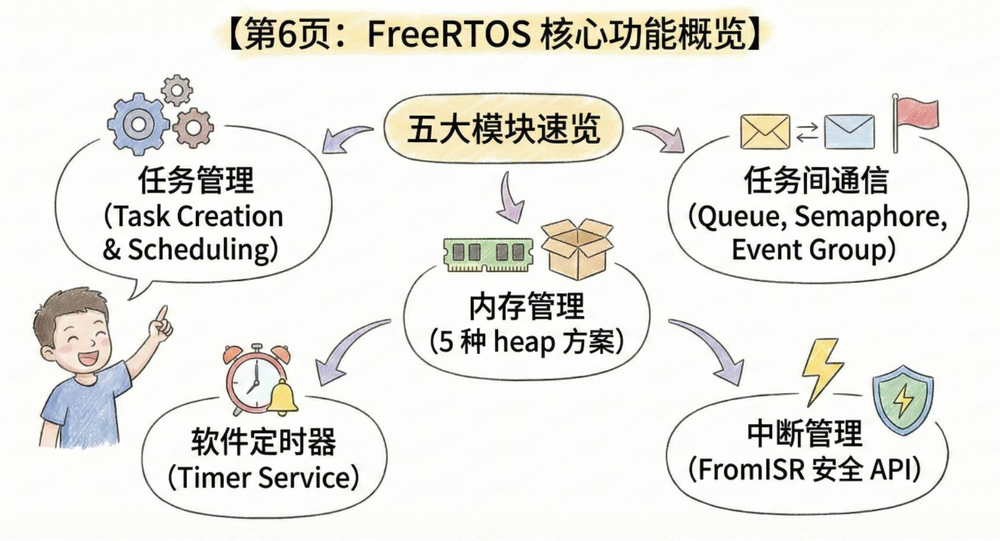

*来源：`02freeRTOS介绍.pptx` 第10页，裁去页眉页脚。*

五大模块构成后续课程的主要内容。先知道每个模块负责什么，再学习具体接口，能够避免把所有多任务问题都归结为“创建任务”。

| 模块 | 解决的问题 | 课件列出的内容 |
|---|---|---|
| 任务管理 | 哪些工作独立运行，何时获得处理器？ | 任务创建与调度（Task Creation & Scheduling） |
| 任务间通信 | 任务怎样传递数据、通知事件并相互协调？ | 消息队列、信号量、事件组（Queue、Semaphore、Event Group） |
| 内存管理 | 内核对象所需内存怎样分配和管理？ | 五种 `heap` 方案 |
| 中断管理 | 中断怎样与任务、内核机制配合？ | 带 `FromISR` 后缀的中断环境专用 API |
| 软件定时器 | 怎样在指定时间触发软件处理？ | 定时器服务（Timer Service） |

### 10.1 任务管理与任务间通信

任务管理负责组织执行，通信与同步负责组织协作。两个任务都能运行，并不代表它们已经能够正确交换数据或共同操作一个资源。

后续课程会区分传递具体数据、通知一个事件、记录事件次数和保护共享资源等需求，再分别使用消息队列、不同信号量及事件组。

### 10.2 内存、中断与软件定时器

创建内核对象需要考虑内存从哪里来、是否能够成功分配。中断处理则处在不同于普通任务的执行环境，使用内核接口时需要选择适用于中断的 API，并满足对应条件。

软件定时器提供定时触发的软件机制，由定时器服务处理。这一模块与任务调度配合，具体创建、启动、停止和使用要求在第10篇展开。

本篇只建立模块职责，不提前展开后续章节的配置和调用代码。


## 11. FreeRTOS官网与学习资源

课件提供的官网入口是 [FreeRTOS 官网](https://www.freertos.org/)。截图中可见文档、下载、GitHub 和社区等入口。

| 学习时遇到的问题 | 优先查找的资料 |
|---|---|
| 需要获取源码或示例工程 | 官网下载及源码仓库入口 |
| 不清楚某个接口怎样使用 | 官方文档中的接口说明、参数和使用条件 |
| 需要理解内核机制或移植方式 | 内核文档、移植说明与对应平台示例 |
| 遇到具体工程问题 | 先核对课程工程与官方资料，再查社区讨论 |

结合课程学习时，应把资料与工程中实际使用的 FreeRTOS 版本对应起来。下一篇会进入源码版本、核心文件、平台相关目录和工程导入，届时再记录具体文件及操作。


## 12. 课件小结与下一步

课件最后归纳了 FreeRTOS 的轻量、开源、低资源占用和实时调度能力，强调它在资源受限 MCU 上的定位，以及跨架构支持、社区和学习资料的作用。

本篇建立的主线是：裸机多任务工作增多后，执行时间和代码耦合更难控制；FreeRTOS 通过任务调度组织执行，再用通信、内存、中断和软件定时器等模块支持任务协作。

课程最终要求把这些机制应用到平衡球项目中。下一篇 **02-开发环境准备与FreeRTOS源码导入**，先解决源码获取、工程结构和库文件导入问题，为实际移植做好准备。
